# Práctica 3: predicción temprana de la situación académica 

La deserción estudiantil y el bajo rendimiento académico representan algunos de los principales desafíos que enfrentan las instituciones de educación superior. Estos fenómenos no solamente afectan el desarrollo profesional y personal de los estudiantes, sino que también generan consecuencias económicas y sociales tanto para las instituciones educativas como para la sociedad. Por esta razón, identificar oportunamente a los estudiantes que presentan dificultades durante su formación académica se ha convertido en un tema de interés para la investigación educativa. En este contexto, las técnicas de minería de datos y aprendizaje automático ofrecen herramientas que permiten analizar grandes cantidades de información académica e identificar patrones relacionados con el desempeño y la permanencia estudiantil (Alban & Mauricio, 2019).

El presente trabajo aborda el problema de la predicción temprana de la situación académica de estudiantes universitarios utilizando el conjunto de datos Predict Students' Dropout and Academic Success, disponible en el repositorio de aprendizaje automático de la Universidad de California en Irvine (UCI). Este conjunto contiene información de 4,424 estudiantes de licenciatura del Instituto Politécnico de Portalegre, Portugal, e integra características relacionadas con sus antecedentes académicos, información demográfica y condiciones socioeconómicas (Realinho et al., 2021).

Objetivo. Al cierre del primer semestre, predecir la situación que tendrá un estudiante al final de la duración normal de su carrera: graduate, dropout o enrolled.

Datos. 4 424 estudiantes de licenciatura del Instituto Politécnico de Portalegre (Portugal), ciclos 2008/09–2018/19 ([UCI 697](https://archive.ics.uci.edu/dataset/697)). Se usan 3 539 para entrenamiento (con Target) y 885 para prueba (sin Target).

Clasificadores comparados (únicamente los vistos en la unidad): árbol de decisión, Naive Bayes, kNN, SVM y regresión logística. Sin ensambles ni redes neuronales.

Métrica principal: F1 macro (promedio no ponderado del F1 de las tres clases), porque la clase enrolled es minoritaria y la exactitud la favorecería menos de lo debido.

In [1]:
import os, re, sys, time, platform, warnings
os.environ["PYTHONWARNINGS"] = "ignore"     
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import loguniform, uniform, randint

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, KBinsDiscretizer, PowerTransformer
from sklearn.feature_selection import SelectKBest, f_classif, chi2
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, RandomizedSearchCV
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB, ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

SEED = 42
np.random.seed(SEED)
N_ITER = int(os.environ.get("N_ITER", 80))  
N_FOLDS = 5
assert N_ITER >= 50

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("Versiones:")
for n, m in [("python", None), ("numpy", np), ("pandas", pd), ("scipy", scipy), ("scikit-learn", sklearn), ("matplotlib", matplotlib)]:
    print(f"  {n:13s}", platform.python_version() if m is None else m.__version__)
print("Semilla:", SEED, "| configuraciones por clasificador:", N_ITER, "| pliegues:", N_FOLDS, "| CPUs:", os.cpu_count())

Versiones:
  python        3.13.3
  numpy         2.2.5
  pandas        2.3.3
  scipy         1.18.1
  scikit-learn  1.9.1
  matplotlib    3.10.1
Semilla: 42 | configuraciones por clasificador: 80 | pliegues: 5 | CPUs: 12


# Descripción del problema y de los datos

In [2]:
def find_data_dir():
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        train_file = folder / "desercion-entrenamiento.csv"
        test_file = folder / "desercion-prueba.csv"

        if train_file.is_file() and test_file.is_file():
            return folder

    raise FileNotFoundError(
        "No se encontraron los archivos CSV en la carpeta actual.\n"
        f"Directorio actual de Python: {current}"
    )


DATA = find_data_dir()
norm = lambda c: re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_")

train_raw = pd.read_csv(DATA / "desercion-entrenamiento.csv", sep=None, engine="python")
test_raw  = pd.read_csv(DATA / "desercion-prueba.csv", sep=None, engine="python")
train = train_raw.rename(columns=norm)
test  = test_raw.rename(columns=norm)

if "id" in test.columns:
    test_ids = test["id"].copy()
else:
    print("AVISO: la prueba no trae columna 'id'; se usa el índice de fila.")
    test_ids = pd.Series(np.arange(len(test)), name="id")

y = train["target"].astype(str).str.strip().str.lower().reset_index(drop=True)
CLASSES = sorted(y.unique())
print("Clases:", CLASSES)

sem2_cols = [c for c in train.columns if "2nd_sem" in c]
feat_s1 = [c for c in train.columns if c not in ("id", "target") and c not in sem2_cols]
missing = [c for c in feat_s1 if c not in test.columns]
assert not missing, f"Faltan en la prueba: {missing}"
leak = [c for c in test.columns if "2nd_sem" in c]
assert not leak, "La prueba no debería traer atributos del 2º semestre"

X      = train[feat_s1].reset_index(drop=True)
X_full = train[feat_s1 + sem2_cols].reset_index(drop=True)
X_test = test[feat_s1].reset_index(drop=True)
print(f"Entrenamiento: {X.shape[0]} filas x {X.shape[1]} atributos (1er semestre) + {len(sem2_cols)} del 2º semestre")
print(f"Prueba:        {X_test.shape[0]} filas x {X_test.shape[1]} atributos")
print("Valores faltantes (train/test):", int(X_full.isna().sum().sum()), "/", int(X_test.isna().sum().sum()),
      "| duplicados en train:", int(X_full.duplicated().sum()))


Clases: ['dropout', 'enrolled', 'graduate']
Entrenamiento: 3539 filas x 30 atributos (1er semestre) + 6 del 2º semestre
Prueba:        885 filas x 30 atributos
Valores faltantes (train/test): 0 / 0 | duplicados en train: 0


In [3]:

NOMINAL = ["marital_status", "application_mode", "course", "previous_qualification", "nacionality",
           "mother_s_qualification", "father_s_qualification", "mother_s_occupation", "father_s_occupation"]
BINARY  = ["daytime_evening_attendance", "displaced", "educational_special_needs", "debtor",
           "tuition_fees_up_to_date", "gender", "scholarship_holder", "international"]
CONTINUOUS = ["previous_qualification_grade", "admission_grade", "unemployment_rate", "inflation_rate", "gdp"] + \
             [c for c in X_full.columns if c.endswith("_grade")]

def tipo(c):
    if c in NOMINAL: return "nominal (código entero)"
    if c in BINARY: return "binario"
    if c in CONTINUOUS: return "continuo"
    if c == "application_order": return "ordinal"
    return "discreto (conteo)"

info = pd.DataFrame({"tipo": [tipo(c) for c in X_full.columns],
                     "n_valores": [X_full[c].nunique() for c in X_full.columns],
                     "disponible_en": ["1er sem." if c in feat_s1 else "solo entrenamiento (2º sem.)" for c in X_full.columns]},
                    index=X_full.columns)
unknown = [c for c in NOMINAL + BINARY if c not in X_full.columns]
print("Atributos esperados que no están en el archivo:", unknown)
display(info.groupby(["tipo", "disponible_en"]).size().unstack(fill_value=0))
display(info.loc[[c for c in X_full.columns if c in NOMINAL]].T)

Atributos esperados que no están en el archivo: []


disponible_en,1er sem.,solo entrenamiento (2º sem.)
tipo,,
binario,8,0
continuo,6,1
discreto (conteo),6,5
nominal (código entero),9,0
ordinal,1,0


,marital_status,application_mode,course,previous_qualification,nacionality,mother_s_qualification,father_s_qualification,mother_s_occupation,father_s_occupation
tipo,nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero),nominal (código entero)
n_valores,6,17,17,17,18,26,32,31,45
disponible_en,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.,1er sem.


,n,%
target,,
dropout,1137,32.1
enrolled,635,17.9
graduate,1767,49.9


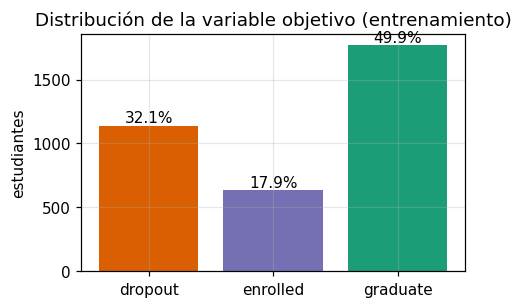

In [4]:
cnt = y.value_counts().reindex(CLASSES)
dist = pd.DataFrame({"n": cnt, "%": (100 * cnt / cnt.sum()).round(1)})
display(dist)
fig, ax = plt.subplots(figsize=(4.5, 2.8))
ax.bar(dist.index, dist["n"], color=["#d95f02", "#7570b3", "#1b9e77"][:len(dist)])
for i, v in enumerate(dist["n"]): ax.text(i, v, f"{dist['%'].iloc[i]}%", ha="center", va="bottom")
ax.set_title("Distribución de la variable objetivo (entrenamiento)"); ax.set_ylabel("estudiantes"); plt.show()

Lectura de los datos.

* Desbalance moderado: graduate es la clase mayoritaria; enrolled es la minoritaria. Por eso la métrica es F1 macro y se prueban pesos por clase.
* Tipos: nueve atributos son nominales codificados como enteros (estado civil, modo de solicitud, carrera, calificación previa, nacionalidad, estudios y ocupación de los padres). Esos enteros no tienen orden ni distancia: tratarlos como números sería un error para kNN, SVM, regresión logística y Naive Bayes gaussiano. Ocho atributos son binarios, application_order es ordinal, hay varios conteos de unidades curriculares y algunos continuos (notas, macroeconomía).
* Información al momento de decidir: al cierre del primer semestre se conocen los atributos socio-demográficos y de ingreso, los macroeconómicos y los seis atributos académicos del 1er semestre. Los seis del 2º semestre no existen todavía, por eso desercion-prueba.csv no los trae y no se usan para entrenar el clasificador final (hacerlo sería una fuga de información respecto al momento de decisión). Solo se usan en la sección 8, para estimar cuánto ayudaría esperar.
* Cardinalidad alta en ocupaciones y calificaciones de los padres: se agrupan las categorías raras (frecuencia < 20) para que el modelo no memorice categorías casi únicas y para que categorías no vistas en la prueba tengan un destino definido.

# Preprocesamiento por clasificador

Todo el preprocesamiento vive dentro del Pipeline, de modo que en cada pliegue se ajusta solo con los datos de entrenamiento del pliegue.

| Paso común | Qué hace | Por qué |
|---|---|---|
| FeatureAdder | Añade tasas por semestre disponible: aprobadas/inscritas, evaluadas/inscritas, aprobadas/evaluadas | El conteo absoluto de aprobadas depende de cuántas materias se inscribieron; la **tasa** es la señal de rendimiento. Los modelos lineales y de distancias no pueden construir cocientes por sí solos. |

| Clasificador | Nominales | Numéricos | Selección | Justificación |
|---|---|---|---|---|
| Árbol | One-hot (agrupando raras) | Sin escalar | — | Los cortes de un árbol son invariantes a escala; one-hot evita imponer un orden falso a los códigos. |
| Naive Bayes | *Gaussiano/Complement:* one-hot. *Categórico:* ordinal con categorías raras agrupadas | *Gaussiano:* estandarizar o Yeo-Johnson. *Complement:* min-max (no negativos). *Categórico:* **discretización** (cuantiles/uniforme) y binarios tal cual | `SelectKBest` opcional | Cada variante exige un tipo de dato distinto. La independencia condicional se viola por las variables redundantes del semestre, y la selección de atributos la mitiga. |
| kNN | One-hot | `StandardScaler` | `SelectKBest` opcional | La distancia es sensible a la escala; y con muchas columnas irrelevantes las distancias se diluyen. |
| SVM | One-hot | `StandardScaler` | — | Los kernels dependen de distancias/productos punto: requieren escalas comparables. |
| Regresión logística | One-hot | `StandardScaler` | — | La penalización L1/L2 actúa sobre los coeficientes y solo es justa si los atributos están en la misma escala. |

In [5]:
class FeatureAdder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        for s in ("1st", "2nd"):
            p = f"curricular_units_{s}_sem_"
            if all(p + k in X.columns for k in ("enrolled", "approved", "evaluations")):
                enr = X[p + "enrolled"].replace(0, np.nan)
                ev  = X[p + "evaluations"].replace(0, np.nan)
                X[f"tasa_aprob_{s}"]      = (X[p + "approved"] / enr).fillna(0.0)
                X[f"tasa_eval_{s}"]       = (X[p + "evaluations"] / enr).fillna(0.0)
                X[f"tasa_aprob_eval_{s}"] = (X[p + "approved"] / ev).fillna(0.0)
        return X

class SafeOrdinalEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, min_frequency=20):
        self.min_frequency = min_frequency
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.maps_ = []
        for j in range(X.shape[1]):
            vc = X.iloc[:, j].value_counts()
            keep = vc[vc >= self.min_frequency].index
            self.maps_.append({v: i + 1 for i, v in enumerate(keep)})
        return self
    def transform(self, X):
        X = pd.DataFrame(X)
        out = np.zeros(X.shape, dtype=int)
        for j, m in enumerate(self.maps_):
            out[:, j] = X.iloc[:, j].map(m).fillna(0).astype(int).to_numpy()
        return out

class SafeCategoricalNB(ClassifierMixin, BaseEstimator):
    def __init__(self, alpha=1.0, fit_prior=True):
        self.alpha = alpha
        self.fit_prior = fit_prior
    def fit(self, X, y):
        X = np.clip(np.asarray(X).astype(int), 0, None)
        self.n_cat_ = X.max(axis=0) + 1
        self.nb_ = CategoricalNB(alpha=self.alpha, fit_prior=self.fit_prior, min_categories=self.n_cat_).fit(X, y)
        self.classes_ = self.nb_.classes_
        return self
    def _p(self, X):
        return np.clip(np.asarray(X).astype(int), 0, self.n_cat_ - 1)
    def predict(self, X):
        return self.nb_.predict(self._p(X))
    def predict_proba(self, X):
        return self.nb_.predict_proba(self._p(X))

def sel_nominal(df): return [c for c in df.columns if c in NOMINAL]
def sel_numeric(df): return [c for c in df.columns if c not in NOMINAL]
def sel_binary(df):  return [c for c in df.columns if c in BINARY]
def sel_cont(df):    return [c for c in df.columns if c not in NOMINAL and c not in BINARY]

def OHE():
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)

def prep_tree():     
    return ColumnTransformer([("nom", OHE(), sel_nominal), ("num", "passthrough", sel_numeric)], verbose_feature_names_out=False)
def prep_scaled():   
    return ColumnTransformer([("nom", OHE(), sel_nominal), ("num", StandardScaler(), sel_numeric)], verbose_feature_names_out=False)
def prep_gauss(power):
    num = PowerTransformer(method="yeo-johnson") if power else StandardScaler()
    return ColumnTransformer([("nom", OHE(), sel_nominal), ("num", num, sel_numeric)], verbose_feature_names_out=False)
def prep_complement():
    return ColumnTransformer([("nom", OHE(), sel_nominal), ("num", MinMaxScaler(), sel_numeric)], verbose_feature_names_out=False)
def prep_categorical():
    return ColumnTransformer([("nom", SafeOrdinalEncoder(min_frequency=20), sel_nominal),
                              ("bin", "passthrough", sel_binary),
                              ("cont", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile"), sel_cont)])

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X, y))
print("Tamaños de validación por pliegue:", [len(v) for _, v in folds])

Tamaños de validación por pliegue: [708, 708, 708, 708, 707]


# Espacios de búsqueda

Búsqueda aleatoria (RandomizedSearchCV) con scoring="f1_macro", los mismos pliegues para todos y N_ITER configuraciones por clasificador (≥ 50). Los espacios son listas de sub-espacios: cada sub-espacio fija una variante (kernel, tipo de regularización, variante de Naive Bayes, con o sin selección) y se sortea uniformemente entre ellos.

| Clasificador | Hiperparámetros y rangos |
|---|---|
| **Árbol** | `criterion` {gini, entropy, log_loss}; `max_depth` {2…20, None}; **poda previa**: `min_samples_leaf` U{1..40}, `min_samples_split` U{2..40}; **poda posterior**: `ccp_alpha` log-U[1e-5, 5e-2]; `max_features` {None, sqrt, 0.5}; `class_weight` {None, balanced, enrolled×2, enrolled×3} |
| **Naive Bayes** | **Variante** {Gaussiano (estándar o Yeo-Johnson), Categórico (discretizado: 3–10 bins, cuantil/uniforme), Complement}; **suavizado**: `var_smoothing` log-U[1e-9, 1] (gaussiano), `alpha` log-U[1e-3, 10] (categórico/complement); priors / `fit_prior`; `SelectKBest` k ∈ {…, todos} |
| **kNN** | `n_neighbors` U{1..80}; `weights` {uniform, distance}; `metric` {euclidean, manhattan, chebyshev, cosine}; `SelectKBest` k ∈ {10, 20, 35, 50, todos}. *(kNN no admite `class_weight`.)* |
| **SVM** | `kernel` {linear, rbf, poly}; `C` log-U (linear [1e-3,5], rbf [1e-2,1e3], poly [1e-2,10]); `gamma` log-U[1e-4, 1] (rbf), [1e-4, 0.1] (poly); `degree` {2,3}; `coef0` {0,1}; `class_weight` igual que el árbol |
| **Regresión logística** | **regularización** {L2, L1, elastic-net (mezcla ∈ [0.1, 0.9])}; `C` log-U[1e-3, 10]; `class_weight` igual que el árbol; solver `saga` (`max_iter`=500) (admite los tres tipos) |

class_weight incluye, además de balanced, pesos manuales para enrolled, la clase difícil: con F1 macro puede convenir sobre-ponderarla más allá de lo "balanceado".

In [6]:
CW = [None, "balanced", {"enrolled": 2.0}, {"enrolled": 3.0}]
FEAT = ("feat", FeatureAdder())

pipe_tree = Pipeline([FEAT, ("prep", prep_tree()), ("clf", DecisionTreeClassifier(random_state=SEED))])
space_tree = {
    "clf__criterion": ["gini", "entropy", "log_loss"],
    "clf__max_depth": list(range(2, 21)) + [None],
    "clf__min_samples_leaf": randint(1, 41),
    "clf__min_samples_split": randint(2, 41),
    "clf__ccp_alpha": loguniform(1e-5, 5e-2),
    "clf__max_features": [None, "sqrt", 0.5],
    "clf__class_weight": CW,
}

pipe_nb = Pipeline([FEAT, ("prep", prep_gauss(False)), ("sel", "passthrough"), ("clf", GaussianNB())])
nb_gauss = {"prep": [prep_gauss(False), prep_gauss(True)], "clf": [GaussianNB()],
            "clf__var_smoothing": loguniform(1e-9, 1.0), "clf__priors": [None, [1/3, 1/3, 1/3]]}
nb_cat   = {"prep": [prep_categorical()], "prep__cont__n_bins": [3, 4, 5, 6, 8, 10], "prep__cont__strategy": ["quantile", "uniform"],
            "clf": [SafeCategoricalNB()], "clf__alpha": loguniform(1e-3, 10), "clf__fit_prior": [True, False]}
nb_comp  = {"prep": [prep_complement()], "clf": [ComplementNB()], "clf__alpha": loguniform(1e-3, 10)}
space_nb = []
for base, scorer in [(nb_gauss, f_classif), (nb_cat, chi2), (nb_comp, f_classif)]:
    space_nb.append(dict(base, sel=["passthrough"]))                                       
    space_nb.append(dict(base, sel=[SelectKBest(scorer)], sel__k=[8, 12, 16, 24, 32, "all"]))  

pipe_knn = Pipeline([FEAT, ("prep", prep_scaled()), ("sel", "passthrough"), ("clf", KNeighborsClassifier())])
knn_common = {"clf__n_neighbors": randint(1, 81), "clf__weights": ["uniform", "distance"],
              "clf__metric": ["euclidean", "manhattan", "chebyshev", "cosine"]}
space_knn = [dict(knn_common, sel=["passthrough"]),
             dict(knn_common, sel=[SelectKBest(f_classif)], sel__k=[10, 20, 35, 50, "all"])]

pipe_svm = Pipeline([FEAT, ("prep", prep_scaled()), ("clf", SVC(cache_size=1000, max_iter=100000, random_state=SEED))])
space_svm = [
    {"clf__kernel": ["linear"], "clf__C": loguniform(1e-3, 5.0), "clf__class_weight": CW},
    {"clf__kernel": ["rbf"], "clf__C": loguniform(1e-2, 1e3), "clf__gamma": loguniform(1e-4, 1.0), "clf__class_weight": CW},
    {"clf__kernel": ["poly"], "clf__C": loguniform(1e-2, 10), "clf__gamma": loguniform(1e-4, 1e-1),
     "clf__degree": [2, 3], "clf__coef0": [0.0, 1.0], "clf__class_weight": CW},
]

SK_VER = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
pipe_lr = Pipeline([FEAT, ("prep", prep_scaled()), ("clf", LogisticRegression(solver="saga", max_iter=500, tol=1e-3))])
lr_common = {"clf__C": loguniform(1e-3, 10.0), "clf__class_weight": CW}
if SK_VER >= (1, 8):    
    space_lr = [dict(lr_common, clf__l1_ratio=[0.0]), dict(lr_common, clf__l1_ratio=[1.0]),
                dict(lr_common, clf__l1_ratio=uniform(0.1, 0.8))]
else:
    space_lr = [dict(lr_common, clf__penalty=["l2"]), dict(lr_common, clf__penalty=["l1"]),
                dict(lr_common, clf__penalty=["elasticnet"], clf__l1_ratio=uniform(0.1, 0.8))]

PIPES  = {"Árbol": pipe_tree, "Naive Bayes": pipe_nb, "kNN": pipe_knn, "SVM": pipe_svm, "Regresión logística": pipe_lr}
SPACES = {"Árbol": space_tree, "Naive Bayes": space_nb, "kNN": space_knn, "SVM": space_svm, "Regresión logística": space_lr}
print({k: (len(v) if isinstance(v, list) else 1) for k, v in SPACES.items()}, "<- sub-espacios por clasificador")

{'Árbol': 1, 'Naive Bayes': 6, 'kNN': 2, 'SVM': 3, 'Regresión logística': 3} <- sub-espacios por clasificador


## 4. Optimización de hiperparámetros (mismos pliegues para los cinco)

In [7]:
def run_search(name, Xd, yd, n_iter=N_ITER):
    rs = RandomizedSearchCV(PIPES[name], SPACES[name], n_iter=n_iter, scoring="f1_macro", cv=folds,   
                            n_jobs=-1, random_state=SEED, refit=True, error_score=np.nan)
    t0 = time.perf_counter()
    rs.fit(Xd, yd)
    return rs, time.perf_counter() - t0

RES = {}
for name in PIPES:
    rs, secs = run_search(name, X, y)
    s = rs.cv_results_["mean_test_score"]
    RES[name] = {"search": rs, "time": secs}
    print(f"{name:20s} configs={len(s):3d} (fallidas={int(np.isnan(s).sum())})  mejor F1 macro CV={rs.best_score_:.4f}  tiempo={secs:6.1f}s")
    print("   mejores hiperparámetros:", {k: (type(v).__name__ if hasattr(v, "fit") else v) for k, v in rs.best_params_.items()})

Árbol                configs= 80 (fallidas=0)  mejor F1 macro CV=0.6568  tiempo=   8.0s
   mejores hiperparámetros: {'clf__ccp_alpha': np.float64(0.00044578143689879266), 'clf__class_weight': {'enrolled': 2.0}, 'clf__criterion': 'log_loss', 'clf__max_depth': 12, 'clf__max_features': None, 'clf__min_samples_leaf': 36, 'clf__min_samples_split': 25}
Naive Bayes          configs= 80 (fallidas=0)  mejor F1 macro CV=0.6560  tiempo=   7.1s
   mejores hiperparámetros: {'clf': 'SafeCategoricalNB', 'clf__alpha': np.float64(0.057624872164786026), 'clf__fit_prior': True, 'prep': 'ColumnTransformer', 'prep__cont__n_bins': 6, 'prep__cont__strategy': 'quantile', 'sel': 'SelectKBest', 'sel__k': 16}
kNN                  configs= 80 (fallidas=0)  mejor F1 macro CV=0.6399  tiempo=   5.7s
   mejores hiperparámetros: {'clf__metric': 'cosine', 'clf__n_neighbors': 25, 'clf__weights': 'uniform', 'sel': 'SelectKBest', 'sel__k': 20}
SVM                  configs= 80 (fallidas=0)  mejor F1 macro CV=0.6871  tiempo

Izquierda: mejor F1 macro alcanzado (línea) contra el número de configuraciones evaluadas; los puntos son el F1 macro de cada configuración. Una meseta significa que las últimas configuraciones ya no mejoran el máximo. Derecha: el F1 macro de validación contra el hiperparámetro más influyente de cada modelo.

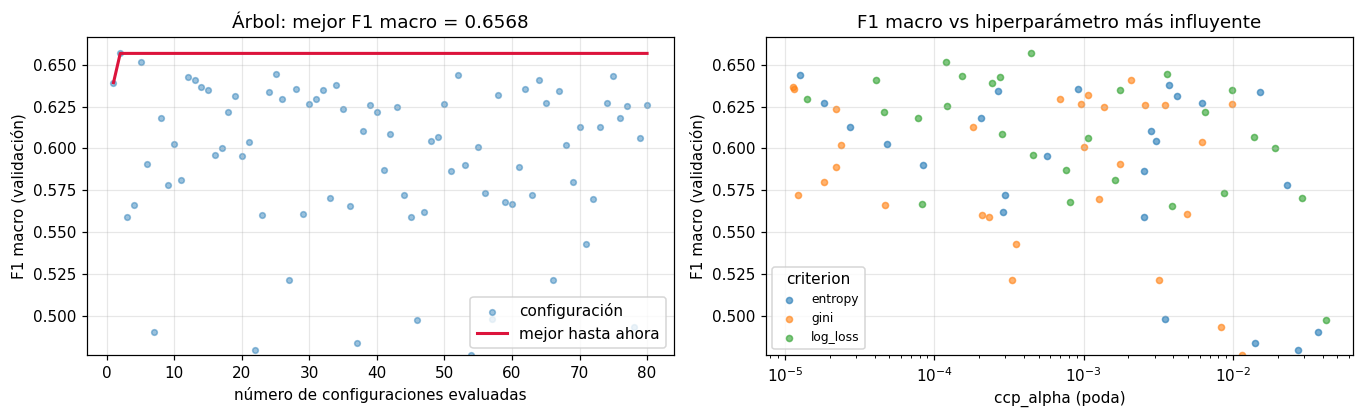

   la mejor configuración apareció en la #2 de 80; mejora entre la #40 y la #80: +0.0000


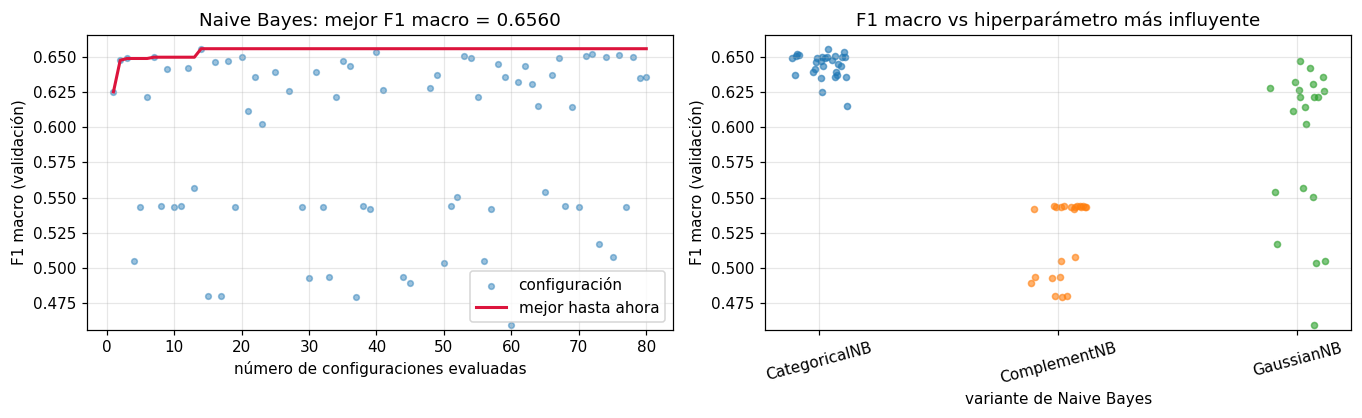

   la mejor configuración apareció en la #14 de 80; mejora entre la #40 y la #80: +0.0000


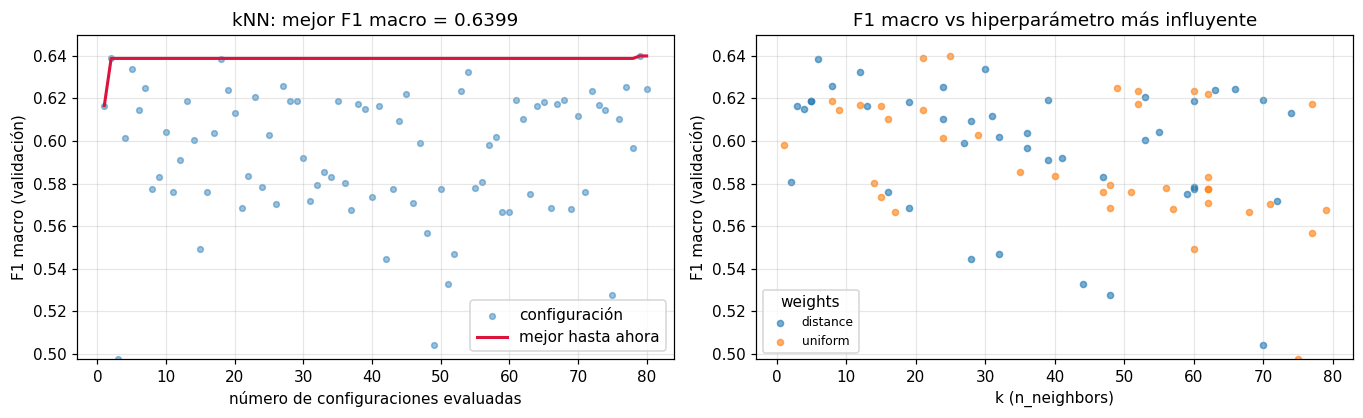

   la mejor configuración apareció en la #79 de 80; mejora entre la #40 y la #80: +0.0012


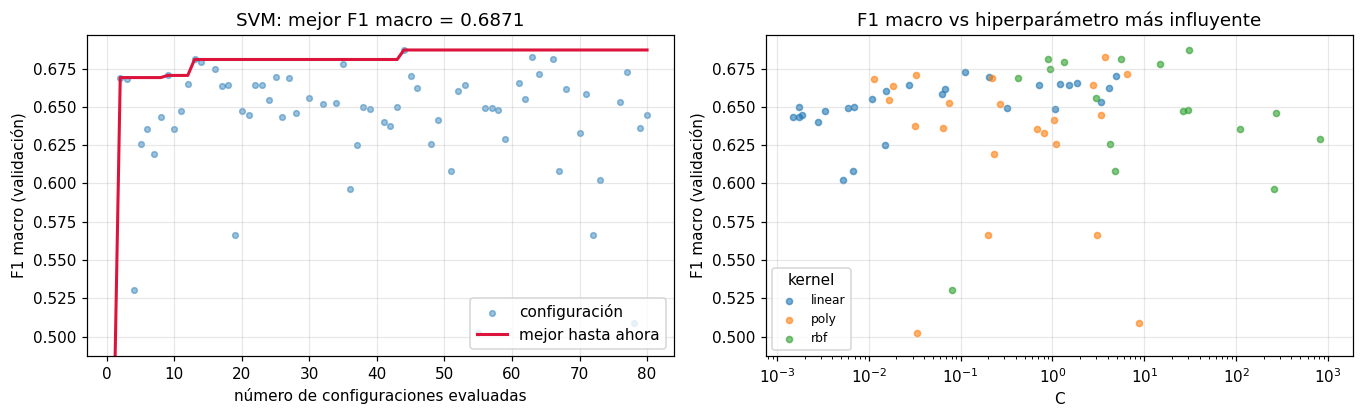

   la mejor configuración apareció en la #44 de 80; mejora entre la #40 y la #80: +0.0062


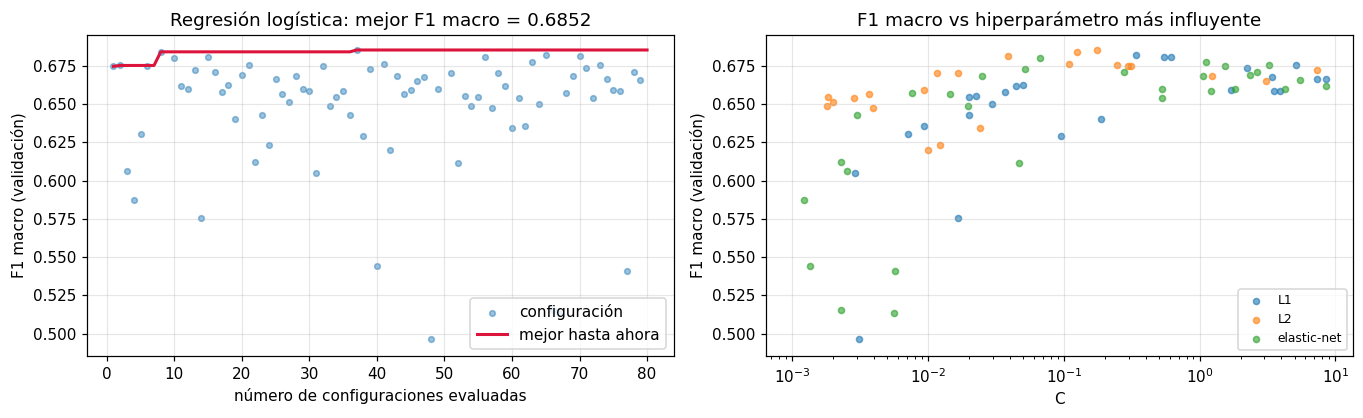

   la mejor configuración apareció en la #37 de 80; mejora entre la #40 y la #80: +0.0000


In [8]:
def plateau_figure(name, xcol=None, xlog=False, hue=None, hue_fn=None, xlabel=None):
    res = pd.DataFrame(RES[name]["search"].cv_results_)
    s = res["mean_test_score"].to_numpy(float)
    ok = ~np.isnan(s)
    it = np.arange(1, len(s) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
    best_so_far = np.fmax.accumulate(np.where(ok, s, -np.inf))
    ax[0].scatter(it[ok], s[ok], s=14, alpha=.45, label="configuración")
    ax[0].plot(it, best_so_far, color="crimson", lw=2, label="mejor hasta ahora")
    ax[0].set_xlabel("número de configuraciones evaluadas"); ax[0].set_ylabel("F1 macro (validación)")
    ax[0].set_title(f"{name}: mejor F1 macro = {np.nanmax(s):.4f}"); ax[0].legend(loc="lower right")
    ax[0].set_ylim(max(np.nanmin(s), np.nanmax(s) - 0.2), np.nanmax(s) + 0.01)
    h = hue_fn(res) if hue_fn is not None else (res[hue].astype(str) if hue else pd.Series(["todas"] * len(res)))
    h = pd.Series(np.asarray(h), index=res.index)
    if xcol is None:                                 
        cats = sorted(h.unique())
        for i, c in enumerate(cats):
            v = s[(h == c).to_numpy() & ok]
            ax[1].scatter(np.full(len(v), i) + np.random.RandomState(0).uniform(-.12, .12, len(v)), v, s=16, alpha=.6)
        ax[1].set_xticks(range(len(cats))); ax[1].set_xticklabels(cats, rotation=15); ax[1].set_xlabel(xlabel or "variante")
    else:
        x = pd.to_numeric(res[xcol], errors="coerce").to_numpy(float)
        for c in sorted(h.unique()):
            m = (h == c).to_numpy() & ok & ~np.isnan(x)
            ax[1].scatter(x[m], s[m], s=16, alpha=.6, label=str(c))
        if xlog: ax[1].set_xscale("log")
        ax[1].set_xlabel(xlabel or xcol.replace("param_clf__", "")); ax[1].legend(fontsize=8, title=hue and hue.replace("param_clf__", ""))
    ax[1].set_ylabel("F1 macro (validación)"); ax[1].set_ylim(ax[0].get_ylim())
    ax[1].set_title("F1 macro vs hiperparámetro más influyente")
    plt.tight_layout(); plt.show()
    last = np.nanargmax(s) + 1
    print(f"   la mejor configuración apareció en la #{last} de {len(s)}; "
          f"mejora entre la #{len(s)//2} y la #{len(s)}: {np.nanmax(s) - np.nanmax(s[:len(s)//2]):+.4f}")

nb_variant = lambda r: r["param_clf"].map(lambda m: {"SafeCategoricalNB": "CategoricalNB"}.get(type(m).__name__, type(m).__name__))
def lr_reg(r):
    if "param_clf__penalty" in r:
        return r["param_clf__penalty"].astype(str)
    l1 = pd.to_numeric(r["param_clf__l1_ratio"], errors="coerce")
    return l1.map(lambda v: "L2" if v == 0 else ("L1" if v == 1 else "elastic-net"))

plateau_figure("Árbol", "param_clf__ccp_alpha", xlog=True, hue="param_clf__criterion", xlabel="ccp_alpha (poda)")
plateau_figure("Naive Bayes", None, hue_fn=nb_variant, xlabel="variante de Naive Bayes")
plateau_figure("kNN", "param_clf__n_neighbors", hue="param_clf__weights", xlabel="k (n_neighbors)")
plateau_figure("SVM", "param_clf__C", xlog=True, hue="param_clf__kernel", xlabel="C")
plateau_figure("Regresión logística", "param_clf__C", xlog=True, hue_fn=lr_reg, xlabel="C")

In [9]:
for name in ["Árbol", "SVM", "Regresión logística"]:
    res = pd.DataFrame(RES[name]["search"].cv_results_)
    res["class_weight"] = res["param_clf__class_weight"].astype(str)
    t = res.groupby("class_weight")["mean_test_score"].agg(n="count", mejor="max", media="mean").sort_values("mejor", ascending=False)
    print(f"--- {name}"); display(t.round(4))

--- Árbol


,n,mejor,media
class_weight,,,
{'enrolled': 2.0},15,0.6568,0.6046
balanced,19,0.6443,0.6075
None,26,0.6411,0.5843
{'enrolled': 3.0},20,0.6352,0.5897


--- SVM


,n,mejor,media
class_weight,,,
{'enrolled': 2.0},24,0.6871,0.6274
balanced,18,0.6828,0.5855
{'enrolled': 3.0},19,0.6744,0.5016
None,19,0.6644,0.5391


--- Regresión logística


,n,mejor,media
class_weight,,,
{'enrolled': 2.0},24,0.6852,0.6570
balanced,17,0.6760,0.6344
{'enrolled': 3.0},17,0.6705,0.6411
None,22,0.6615,0.5806


# Comparación de los cinco clasificadores optimizados

Para cada mejor configuración se reentrena en cada uno de los mismos 5 pliegues y se obtienen las predicciones de validación. De ahí salen el F1 macro por pliegue (media ± desviación estándar), la sensibilidad (recall de la clase) y la especificidad (1 − tasa de falsos positivos de la clase, en esquema uno-contra-resto) con las predicciones agrupadas de los cinco pliegues.

Como el máximo de una búsqueda es optimista (se eligió porque fue el mejor en esos pliegues), se añade una columna de control: el F1 macro del mismo modelo en pliegues nuevos que no intervinieron en la selección. Es una comprobación, no un conjunto de prueba independiente.

,F1 macro (media),F1 macro (desv.),exactitud,sens_dropout,espec_dropout,sens_enrolled,espec_enrolled,sens_graduate,espec_graduate,F1 macro pliegues nuevos,n_configs,tiempo búsqueda (s)
clasificador,,,,,,,,,,,,
SVM,0.687,0.012,0.736,0.644,0.949,0.562,0.844,0.859,0.797,0.688,80,49.734
Regresión logística,0.685,0.006,0.736,0.676,0.936,0.529,0.853,0.849,0.801,0.686,80,37.467
Árbol,0.657,0.016,0.701,0.615,0.954,0.562,0.792,0.806,0.806,0.654,80,8.037
Naive Bayes,0.656,0.018,0.708,0.661,0.908,0.494,0.843,0.816,0.799,0.664,80,7.137
kNN,0.640,0.019,0.738,0.716,0.920,0.255,0.947,0.926,0.672,0.622,80,5.727


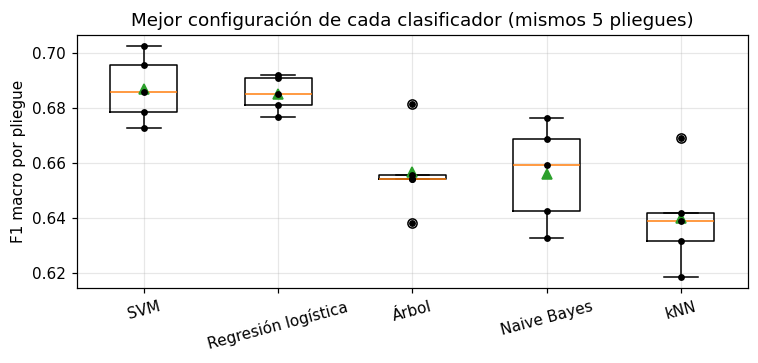

Mejor clasificador por F1 macro de validación cruzada: SVM
Ventaja sobre el segundo (Regresión logística): 0.0019  |  desviación entre pliegues del mejor: 0.0121


In [10]:
def evaluate(est, Xd, yd, fold_list):
    pred = np.empty(len(yd), dtype=object); f1s = []
    for tr, va in fold_list:
        m = clone(est).fit(Xd.iloc[tr], yd.iloc[tr])
        p = m.predict(Xd.iloc[va]); pred[va] = p
        f1s.append(f1_score(yd.iloc[va], p, average="macro"))
    return pred, np.array(f1s)

def sens_spec(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    out = {}
    for i, c in enumerate(labels):
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp; tn = cm.sum() - tp - fn - fp
        out[f"sens_{c}"] = tp / (tp + fn); out[f"espec_{c}"] = tn / (tn + fp)
    return out

fresh = list(RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=3, random_state=SEED + 1).split(X, y))

rows, CVPRED, CVF1 = [], {}, {}
for name, d in RES.items():
    best = d["search"].best_estimator_
    pred, f1s = evaluate(best, X, y, folds)
    _, f1_fresh = evaluate(best, X, y, fresh)
    CVPRED[name], CVF1[name] = pred, f1s
    rows.append({"clasificador": name, "F1 macro (media)": f1s.mean(), "F1 macro (desv.)": f1s.std(ddof=1),
                 "exactitud": accuracy_score(y, pred), **sens_spec(y.to_numpy(), pred, CLASSES),
                 "F1 macro pliegues nuevos": f1_fresh.mean(), "n_configs": len(d["search"].cv_results_["params"]),
                 "tiempo búsqueda (s)": d["time"]})
comp = pd.DataFrame(rows).set_index("clasificador").sort_values("F1 macro (media)", ascending=False)
display(comp.round(3))

fig, ax = plt.subplots(figsize=(7, 3.4))
order = list(comp.index)
ax.boxplot([CVF1[n] for n in order], showmeans=True)
ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order)
for i, n in enumerate(order, 1): ax.scatter(np.full(len(CVF1[n]), i), CVF1[n], color="k", s=12, zorder=3)
ax.set_ylabel("F1 macro por pliegue"); ax.set_title("Mejor configuración de cada clasificador (mismos 5 pliegues)")
plt.setp(ax.get_xticklabels(), rotation=15); plt.tight_layout(); plt.show()

BEST = comp.index[0]
print(f"Mejor clasificador por F1 macro de validación cruzada: {BEST}")
gap = comp["F1 macro (media)"].iloc[0] - comp["F1 macro (media)"].iloc[1]
print(f"Ventaja sobre el segundo ({comp.index[1]}): {gap:.4f}  |  desviación entre pliegues del mejor: {comp['F1 macro (desv.)'].iloc[0]:.4f}")

# Matriz de confusión del mejor clasificador y análisis de la clase "dropout"

La matriz usa predicciones de validación cruzada (cada estudiante es predicho por un modelo que no lo vio en entrenamiento).

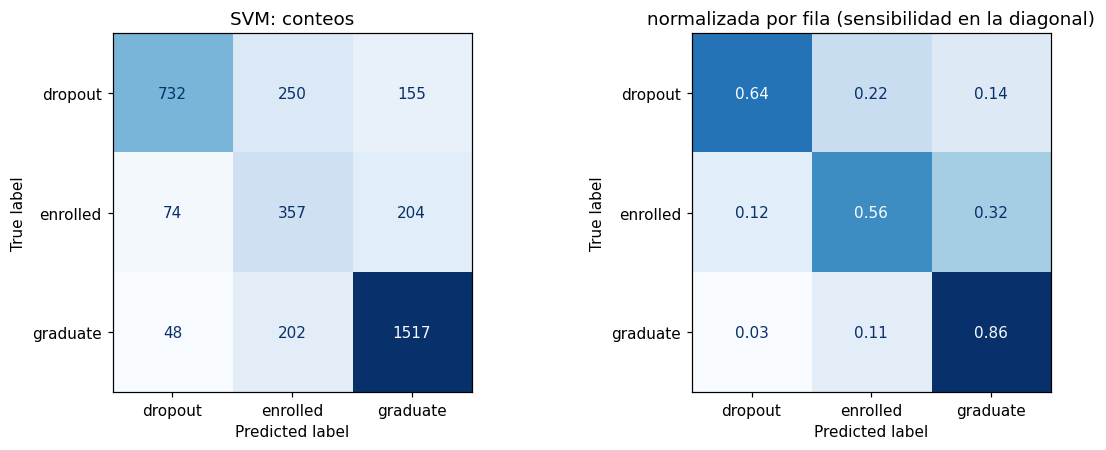

Sensibilidad de dropout: 64.4%. De los desertores reales, 22.0% se predice como 'enrolled' y 13.6% como 'graduate'.
Precisión de dropout: 85.7%. Entre lo que se predice dropout: 8.7% son enrolled, 5.6% son graduate.


In [11]:
pred_best = CVPRED[BEST]
cm = confusion_matrix(y, pred_best, labels=CLASSES)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=CLASSES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[0].set_title(f"{BEST}: conteos"); ax[1].set_title("normalizada por fila (sensibilidad en la diagonal)")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()

i = CLASSES.index("dropout")
row = cm[i] / cm[i].sum()
conf = pd.Series(row, index=CLASSES).drop("dropout")
print(f"Sensibilidad de dropout: {row[i]:.1%}. De los desertores reales, {conf.iloc[0]:.1%} se predice como '{conf.index[0]}' y {conf.iloc[1]:.1%} como '{conf.index[1]}'.")
col = cm[:, i] / cm[:, i].sum()
print(f"Precisión de dropout: {col[i]:.1%}. Entre lo que se predice dropout: " +
      ", ".join(f"{col[j]:.1%} son {c}" for j, c in enumerate(CLASSES) if c != "dropout") + ".")

,dropout → dropout,dropout → enrolled,dropout → graduate,(real enrolled),(real graduate)
curricular_units_1st_sem_approved,1.54,3.38,6.01,4.33,6.25
curricular_units_1st_sem_enrolled,5.72,5.75,6.52,6.01,6.68
tasa_aprob_1st,0.23,0.56,0.82,0.69,0.90
tasa_aprob_eval_1st,0.16,0.36,0.68,0.48,0.76
curricular_units_1st_sem_grade,5.31,10.89,11.26,11.13,12.62
curricular_units_1st_sem_without_evaluations,0.23,0.17,0.10,0.19,0.09
admission_grade,123.74,125.08,130.20,125.34,128.94
tuition_fees_up_to_date,0.50,0.98,0.98,0.95,0.99
debtor,0.30,0.10,0.08,0.11,0.04
scholarship_holder,0.06,0.08,0.28,0.17,0.38


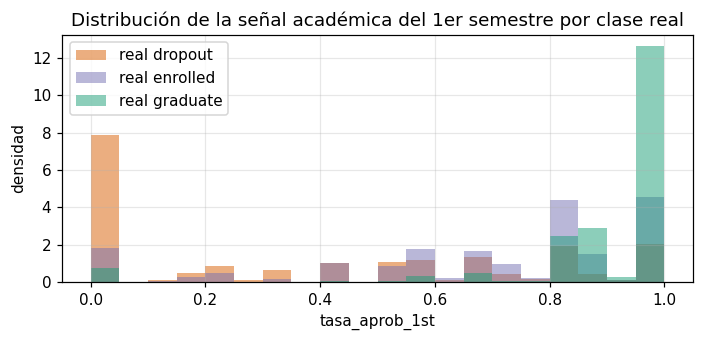

In [12]:
FE = FeatureAdder().transform(X)
cands = ["curricular_units_1st_sem_approved", "curricular_units_1st_sem_enrolled", "tasa_aprob_1st", "tasa_aprob_eval_1st",
         "curricular_units_1st_sem_grade", "curricular_units_1st_sem_without_evaluations", "admission_grade",
         "tuition_fees_up_to_date", "debtor", "scholarship_holder", "age_at_enrollment", "application_order"]
cands = [c for c in cands if c in FE.columns]
dfp = FE[cands].copy(); dfp["real"] = y.values; dfp["pred"] = pred_best
drop = dfp[dfp.real == "dropout"]
prof = {f"dropout → {p}": drop[drop.pred == p][cands].mean() for p in CLASSES if (drop.pred == p).any()}
for c in CLASSES:
    if c != "dropout": prof[f"(real {c})"] = dfp[dfp.real == c][cands].mean()
prof = pd.DataFrame(prof)
prof.loc["n estudiantes"] = [int((drop.pred == p).sum()) for p in CLASSES if (drop.pred == p).any()] + [int((dfp.real == c).sum()) for c in CLASSES if c != "dropout"]
display(prof.round(2))

key = "tasa_aprob_1st" if "tasa_aprob_1st" in FE.columns else cands[0]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for c, colr in zip(CLASSES, ["#d95f02", "#7570b3", "#1b9e77"]):
    ax.hist(FE.loc[(y == c).values, key], bins=20, alpha=.5, density=True, label=f"real {c}", color=colr)
ax.set_xlabel(key); ax.set_ylabel("densidad"); ax.legend(); ax.set_title("Distribución de la señal académica del 1er semestre por clase real")
plt.tight_layout(); plt.show()

In [13]:
others = [c for c in CLASSES if c != "dropout"]
main = conf.idxmax()
out = [f"**Con qué se confunde `dropout`:** principalmente con **{main}** ({conf.max():.1%} de los desertores reales); "
       f"con {[c for c in others if c != main][0]} el {conf.min():.1%}. Sensibilidad de dropout: {row[i]:.1%}; precisión: {col[i]:.1%}."]
if key in prof.index and "dropout → dropout" in prof.columns:
    ok = prof.loc[key, "dropout → dropout"]
    for p in others:
        c = f"dropout → {p}"
        if c in prof.columns and not np.isnan(prof.loc[key, c]):
            mis, real = prof.loc[key, c], prof.loc[key, f"(real {p})"]
            closer = abs(mis - real) < abs(mis - ok)
            out.append(f"- `{key}` medio: desertores detectados = {ok:.2f}; desertores predichos como {p} = {mis:.2f}; estudiantes realmente {p} = {real:.2f}. "
                       + (f"Los desertores confundidos con {p} **se parecen más a los {p} reales que a los desertores detectados** en esta señal: la información del 1er semestre no los distingue."
                          if closer else f"En esta señal siguen más cerca de los desertores detectados que de los {p} reales; la confusión se explica por otros atributos."))
display(Markdown("\n".join(out)))

**Con qué se confunde `dropout`:** principalmente con **enrolled** (22.0% de los desertores reales); con graduate el 13.6%. Sensibilidad de dropout: 64.4%; precisión: 85.7%.
- `tasa_aprob_1st` medio: desertores detectados = 0.23; desertores predichos como enrolled = 0.56; estudiantes realmente enrolled = 0.69. Los desertores confundidos con enrolled **se parecen más a los enrolled reales que a los desertores detectados** en esta señal: la información del 1er semestre no los distingue.
- `tasa_aprob_1st` medio: desertores detectados = 0.23; desertores predichos como graduate = 0.82; estudiantes realmente graduate = 0.90. Los desertores confundidos con graduate **se parecen más a los graduate reales que a los desertores detectados** en esta señal: la información del 1er semestre no los distingue.

Cómo leer este análisis. La clase enrolled es un estado intermedio (alumnos que a la duración normal siguen inscritos, normalmente con avance lento), por lo que sus atributos se traslapan con los de las otras dos clases. Además, parte de la decisión de abandonar depende de eventos posteriores al primer semestre (trabajo, dinero, cambio de carrera) que ningún atributo conocido al cierre del primero contiene: ese techo de información limita a todos los modelos, no solo al mejor. El texto de arriba se calcula con los resultados de esta corrida.

# ¿Conviene esperar al cierre del segundo semestre?

Se usa solo el conjunto de entrenamiento (el único que trae los atributos del 2º semestre). Se compara el mejor clasificador con:

* (a) solo información del 1er semestre (la situación real de decisión).
* (b) 1er + 2º semestre con los mismos hiperparámetros.
* (c) 1er + 2º semestre re-optimizando hiperparámetros.

Cada hiperparámetro se evalúa en los mismos pliegues, de modo que la diferencia por pliegue es una comparación pareada.

In [14]:
best_est = RES[BEST]["search"].best_estimator_
pred_a, f1_a = CVPRED[BEST], CVF1[BEST]
pred_b, f1_b = evaluate(best_est, X_full, y, folds)
rs_c, secs_c = run_search(BEST, X_full, y)
pred_c, f1_c = evaluate(rs_c.best_estimator_, X_full, y, folds)

tab = pd.DataFrame({
    "F1 macro media": [f1_a.mean(), f1_b.mean(), f1_c.mean()],
    "F1 macro desv.": [f1_a.std(ddof=1), f1_b.std(ddof=1), f1_c.std(ddof=1)],
    "exactitud": [accuracy_score(y, p) for p in (pred_a, pred_b, pred_c)],
    **{f"sens_{c}": [sens_spec(y.to_numpy(), p, CLASSES)[f"sens_{c}"] for p in (pred_a, pred_b, pred_c)] for c in CLASSES},
}, index=["(a) solo 1er semestre", "(b) +2º sem., mismos hiperparámetros", "(c) +2º sem., re-optimizado"])
display(tab.round(3))
d = f1_c - f1_a
print(f"Mejora (c)-(a) por pliegue: {np.round(d, 3)}  → media {d.mean():+.4f}, desv. {d.std(ddof=1):.4f}; "
      f"mejora en {int((d > 0).sum())} de {len(d)} pliegues.")
print(f"Mejora relativa de F1 macro: {100 * d.mean() / f1_a.mean():+.1f}%")
for c in CLASSES:
    print(f"  sensibilidad de {c}: {tab.iloc[0][f'sens_{c}']:.3f} → {tab.iloc[2][f'sens_{c}']:.3f}")

,F1 macro media,F1 macro desv.,exactitud,sens_dropout,sens_enrolled,sens_graduate
(a) solo 1er semestre,0.687,0.012,0.736,0.644,0.562,0.859
"(b) +2º sem., mismos hiperparámetros",0.717,0.010,0.764,0.701,0.589,0.867
"(c) +2º sem., re-optimizado",0.717,0.011,0.756,0.722,0.636,0.822


Mejora (c)-(a) por pliegue: [0.025 0.028 0.027 0.045 0.026]  → media +0.0301, desv. 0.0084; mejora en 5 de 5 pliegues.
Mejora relativa de F1 macro: +4.4%
  sensibilidad de dropout: 0.644 → 0.722
  sensibilidad de enrolled: 0.562 → 0.636
  sensibilidad de graduate: 0.859 → 0.822


In [15]:
gain, noise = d.mean(), d.std(ddof=1)
sens_gain = {c: tab.iloc[2][f"sens_{c}"] - tab.iloc[0][f"sens_{c}"] for c in CLASSES}
big = max(sens_gain, key=sens_gain.get)
if gain <= 0:     nivel = "nula o negativa"
elif gain < 0.03: nivel = "modesta"
elif gain < 0.08: nivel = "moderada"
else:             nivel = "grande"
txt = (f"**Resultado:** esperar al 2º semestre cambia el F1 macro de {f1_a.mean():.3f} a {f1_c.mean():.3f} ({gain:+.3f}, {100*gain/f1_a.mean():+.1f}%), "
       f"una ganancia **{nivel}**, que {'supera' if gain > noise else 'no supera'} la desviación pareada entre pliegues ({noise:.3f}) y aparece en {int((d>0).sum())} de {len(d)} pliegues. "
       f"La clase que más gana sensibilidad es **{big}** ({sens_gain[big]:+.3f}).")
display(Markdown(txt))

**Resultado:** esperar al 2º semestre cambia el F1 macro de 0.687 a 0.717 (+0.030, +4.4%), una ganancia **moderada**, que supera la desviación pareada entre pliegues (0.008) y aparece en 5 de 5 pliegues. La clase que más gana sensibilidad es **dropout** (+0.078).

¿Conviene esperar? El número de arriba es solo una parte de la decisión:

* A favor de esperar: los atributos del 2º semestre son el indicio más directo del rendimiento y mejoran la predicción en la magnitud medida arriba.
* En contra: un sistema de alerta temprana solo vale si deja tiempo para actuar (tutorías, becas, apoyo económico, orientación). Esperar retrasa la intervención aproximadamente seis meses, y los desertores que abandonan al terminar el primer año se pierden. Parte de la mejora puede venir de estudiantes que ya se estaban yendo (pocas materias inscritas en el 2º semestre es casi la deserción misma), es decir, información que llega tarde para evitar el abandono.
* Criterio: si la ganancia es modesta y la intervención sirve con estudiantes del 1er semestre, conviene decidir al cierre del primero y usar el segundo como segunda revisión de los casos dudosos. Si es grande y las intervenciones siguen siendo útiles tarde, esperar es razonable. Si es moderada, depende del costo de intervenir a quien no iba a desertar frente al de perder a quien sí.

# Clasificador final y predicciones sobre el conjunto de prueba

Se entrena el mejor clasificador (por F1 macro de validación cruzada) **con todo el conjunto de entrenamiento** y solo con atributos del 1er semestre, y se predice sobre los 885 estudiantes de prueba.

In [16]:
final = clone(RES[BEST]["search"].best_estimator_).fit(X, y)
print("Clasificador final:", BEST)
print("Hiperparámetros:", {k: (type(v).__name__ if hasattr(v, "fit") else v) for k, v in RES[BEST]["search"].best_params_.items()})

pred_test = final.predict(X_test)
sub = pd.DataFrame({"id": test_ids.to_numpy(), "Target": pd.Series(pred_test).astype(str).str.lower().to_numpy()})

assert list(sub.columns) == ["id", "Target"]
assert len(sub) == len(test) and sub["id"].is_unique
assert set(sub["Target"]) <= {"dropout", "enrolled", "graduate"}
if len(sub) != 885: print(f"AVISO: se esperaban 885 filas y hay {len(sub)}")

OUT = DATA / "predicciones.csv"
sub.to_csv(OUT, index=False)
display(sub.head())
cmp = pd.DataFrame({"prueba (predicho) %": sub["Target"].value_counts(normalize=True).reindex(CLASSES) * 100,
                    "entrenamiento (real) %": y.value_counts(normalize=True).reindex(CLASSES) * 100}).round(1)
display(cmp)

Clasificador final: SVM
Hiperparámetros: {'clf__C': np.float64(30.30549375591522), 'clf__class_weight': {'enrolled': 2.0}, 'clf__gamma': np.float64(0.0015977662354833878), 'clf__kernel': 'rbf'}


,id,Target
0,6,graduate
1,12,graduate
2,15,graduate
3,18,enrolled
4,19,graduate


,prueba (predicho) %,entrenamiento (real) %
dropout,23.2,32.1
enrolled,23.2,17.9
graduate,53.7,49.9


# Discusión

In [17]:
r = comp.reset_index()
lines = ["**Resultados de esta ejecución (F1 macro, validación cruzada de 5 pliegues):**", ""]
for _, w in r.iterrows():
    lines.append(f"- **{w['clasificador']}**: {w['F1 macro (media)']:.3f} ± {w['F1 macro (desv.)']:.3f} "
                 f"(pliegues nuevos: {w['F1 macro pliegues nuevos']:.3f}); sensibilidad dropout/enrolled/graduate = "
                 f"{w['sens_dropout']:.2f}/{w['sens_enrolled']:.2f}/{w['sens_graduate']:.2f}; búsqueda: {w['tiempo búsqueda (s)']:.0f} s.")
lines += ["", "**Meseta de cada búsqueda** (mejora del máximo al pasar de la mitad a la totalidad de las configuraciones):", ""]
for n_, d_ in RES.items():
    sc = d_["search"].cv_results_["mean_test_score"]
    lines.append(f"- {n_}: {np.nanmax(sc) - np.nanmax(sc[:len(sc)//2]):+.4f} en la 2ª mitad ({len(sc)} configuraciones).")
top, second = r.iloc[0], r.iloc[1]
within = (top["F1 macro (media)"] - second["F1 macro (media)"]) < top["F1 macro (desv.)"]
lines += ["", f"El mejor es **{top['clasificador']}**. La diferencia con {second['clasificador']} es de "
          f"{top['F1 macro (media)'] - second['F1 macro (media)']:.3f}, " +
          ("**menor que la desviación entre pliegues**: los dos son estadísticamente casi indistinguibles con estos datos."
           if within else "mayor que la desviación entre pliegues."),
          f"Clase más difícil (menor sensibilidad media entre modelos): **{r[[f'sens_{c}' for c in CLASSES]].mean().idxmin().replace('sens_', '')}**."]
display(Markdown("\n".join(lines)))

**Resultados de esta ejecución (F1 macro, validación cruzada de 5 pliegues):**

- **SVM**: 0.687 ± 0.012 (pliegues nuevos: 0.688); sensibilidad dropout/enrolled/graduate = 0.64/0.56/0.86; búsqueda: 50 s.
- **Regresión logística**: 0.685 ± 0.006 (pliegues nuevos: 0.686); sensibilidad dropout/enrolled/graduate = 0.68/0.53/0.85; búsqueda: 37 s.
- **Árbol**: 0.657 ± 0.016 (pliegues nuevos: 0.654); sensibilidad dropout/enrolled/graduate = 0.61/0.56/0.81; búsqueda: 8 s.
- **Naive Bayes**: 0.656 ± 0.018 (pliegues nuevos: 0.664); sensibilidad dropout/enrolled/graduate = 0.66/0.49/0.82; búsqueda: 7 s.
- **kNN**: 0.640 ± 0.019 (pliegues nuevos: 0.622); sensibilidad dropout/enrolled/graduate = 0.72/0.26/0.93; búsqueda: 6 s.

**Meseta de cada búsqueda** (mejora del máximo al pasar de la mitad a la totalidad de las configuraciones):

- Árbol: +0.0000 en la 2ª mitad (80 configuraciones).
- Naive Bayes: +0.0000 en la 2ª mitad (80 configuraciones).
- kNN: +0.0012 en la 2ª mitad (80 configuraciones).
- SVM: +0.0062 en la 2ª mitad (80 configuraciones).
- Regresión logística: +0.0000 en la 2ª mitad (80 configuraciones).

El mejor es **SVM**. La diferencia con Regresión logística es de 0.002, **menor que la desviación entre pliegues**: los dos son estadísticamente casi indistinguibles con estos datos.
Clase más difícil (menor sensibilidad media entre modelos): **enrolled**.

Por qué cada clasificador se comporta como lo hace en este problema:

* Regresión logística. Es un modelo lineal y regularizado. Aquí suele ser competitiva porque la señal principal es casi monótona (más unidades aprobadas, mejores notas y pagos al día → más probabilidad de graduarse) y porque las variables del semestre están muy correlacionadas, cosa que la regularización (L1/L2) maneja bien. Sus pesos por clase y su C son los que más ayudan a enrolled. Es, además, el modelo más interpretable y el más rápido.
* SVM. Con kernel RBF puede modelar no linealidades suaves y fronteras con curvatura; requiere variables escaladas y su costo crece con el número de estudiantes. Con class_weight ajustado mejora la sensibilidad de la clase minoritaria. Si el kernel lineal queda empatado con el RBF, es indicio de que la frontera es esencialmente lineal.
* Árbol de decisión. Captura umbrales y condiciones del tipo "aprobó 0 unidades" y es totalmente interpretable, pero tiene alta varianza: sin poda memoriza. La poda (ccp_alpha, min_samples_leaf, max_depth) es lo que lo hace competitivo; aun así, sus fronteras ortogonales son una aproximación escalonada de una frontera diagonal, y suele quedar por debajo de modelos lineales/kernel bien ajustados.
* Naive Bayes. Supone independencia condicional entre atributos, y aquí se viola de forma fuerte (aprobadas, evaluadas e inscritas por semestre, y los estudios/ocupación de los padres, están ligados). Eso suele producir probabilidades sobreconfiadas, aunque la clasificación puede seguir siendo razonable. La discretización, la selección de atributos y el suavizado lo mitigan; es el más barato de entrenar.
* kNN. Es sensible a la escala y a la dimensionalidad: tras el one-hot hay muchas columnas poco informativas que diluyen las distancias. La selección de atributos y la ponderación por distancia ayudan. No admite pesos por clase, así que tiende a favorecer a la clase mayoritaria, y es el más lento al predecir.

# Conclusiones 

Al comparar los resultados obtenidos mediante F1 macro por pliegue, es importante considerar la diferencia entre los dos modelos con mejor desempeño. En este caso, el SVM obtuvo un F1 macro de 0.687, mientras que la regresión logística alcanzó 0.685, por lo que la diferencia entre ambos es muy pequeña en comparación con la variabilidad de los resultados. Esto indica que no existe una ventaja suficientemente clara para considerar al primero como un ganador definitivo, por lo que también es conveniente tomar en cuenta la simplicidad y la interpretabilidad al seleccionar un modelo.

Asimismo, los resultados muestran que la clase enrolled presenta la menor sensibilidad en los cinco clasificadores evaluados. Esto coincide con la naturaleza intermedia de dicha categoría, cuyos estudiantes pueden compartir características tanto con quienes abandonan sus estudios como con quienes finalmente se gradúan. Por esta razón, distinguir correctamente esta clase representa uno de los principales desafíos del problema de clasificación.

Por otra parte, los pesos asignados a las clases tienen una influencia importante en el desempeño de los modelos que permiten utilizar este parámetro, como el árbol de decisión, SVM y regresión logística. En los resultados obtenidos, el peso adicional asignado a la clase enrolled permitió alcanzar mejores valores de F1 macro en las configuraciones seleccionadas. En el caso de Naive Bayes, el equilibrio entre las clases se aborda mediante los priors y el parámetro fit_prior, que determinan cómo se consideran las probabilidades previas de cada categoría. Estos mecanismos permiten modificar el comportamiento de los clasificadores frente al desbalance de clases.

También es importante considerar el comportamiento de las búsquedas de hiperparámetros. Los resultados muestran que, en la mayoría de los modelos, la mejora obtenida durante la segunda mitad de la búsqueda fue prácticamente nula. Esto indica que el proceso llegó a una meseta y que evaluar más configuraciones similares probablemente no produciría mejoras significativas. En consecuencia, los avances más importantes podrían obtenerse mediante la incorporación de información adicional que permita describir mejor las condiciones académicas de los estudiantes.

Finalmente, debe tenerse en cuenta que el F1 macro obtenido mediante validación cruzada del mejor modelo puede representar una estimación optimista de su desempeño real, debido a que fue seleccionado entre varias decenas de configuraciones evaluadas utilizando los mismos datos. La columna denominada «F1 macro pliegues nuevos» proporciona una referencia adicional sobre la estabilidad de los resultados mediante particiones diferentes, aunque no constituye una evaluación completamente independiente, ya que utiliza el mismo conjunto de datos. Por esta razón, las diferencias de rendimiento entre los modelos deben interpretarse con cautela, considerando la variabilidad de los resultados y no únicamente el valor máximo de F1 macro obtenido.

# Referencias

Alban, M., & Mauricio, D. (2019). Predicting university dropout through data mining: A systematic literature. Indian Journal of Science and Technology, 12(4), 1–12. https://doi.org/10.17485/ijst/2019/v12i4/139729

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). Predict students' dropout and academic success [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89

# Declaracion de uso de IA

Para esta practica se utilizo la inteligencia artificial Anthropic Claude como herramienta de asistencia para la revision, edicion y mejora del formato de texto asi como el apoyo en la toma de sugerencias para la parte del codigo y la correccion de errores.